In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(
    "../data/medical/xray.jpg",
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise FileNotFoundError("Medical image not found.")

In [2]:
gaussian = cv2.GaussianBlur(
    image,
    (5, 5),
    0
)

median = cv2.medianBlur(
    image,
    5
)

In [3]:
sobel_x = cv2.Sobel(
    gaussian,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

sobel_y = cv2.Sobel(
    gaussian,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

magnitude = np.sqrt(
    sobel_x ** 2 + sobel_y ** 2
)

magnitude = cv2.normalize(
    magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

In [4]:
canny_original = cv2.Canny(
    image,
    50,
    150
)

canny_gaussian = cv2.Canny(
    gaussian,
    50,
    150
)

canny_median = cv2.Canny(
    median,
    50,
    150
)

In [5]:
print(
    "Original Canny edge pixels:",
    np.count_nonzero(canny_original)
)

print(
    "Gaussian edge pixels:",
    np.count_nonzero(canny_gaussian)
)

print(
    "Median edge pixels:",
    np.count_nonzero(canny_median)
)

Original Canny edge pixels: 20010
Gaussian edge pixels: 9985
Median edge pixels: 11246


In [6]:
original_edges = np.count_nonzero(canny_original)
gaussian_edges = np.count_nonzero(canny_gaussian)
median_edges = np.count_nonzero(canny_median)

print("Edge Pixel Comparison")
print("-" * 35)
print(f"Original Image  : {original_edges}")
print(f"Gaussian Blur   : {gaussian_edges}")
print(f"Median Filter   : {median_edges}")

Edge Pixel Comparison
-----------------------------------
Original Image  : 20010
Gaussian Blur   : 9985
Median Filter   : 11246


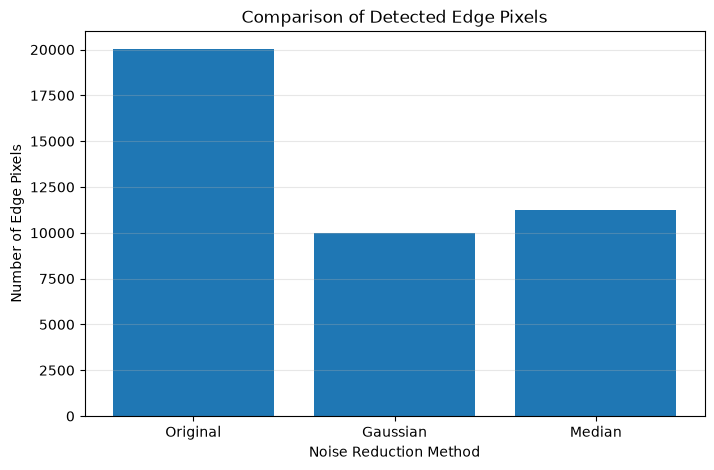

In [7]:
methods = ["Original", "Gaussian", "Median"]
edge_counts = [
    original_edges,
    gaussian_edges,
    median_edges
]

plt.figure(figsize=(8, 5))

plt.bar(methods, edge_counts)

plt.title("Comparison of Detected Edge Pixels")
plt.xlabel("Noise Reduction Method")
plt.ylabel("Number of Edge Pixels")

plt.grid(axis="y", alpha=0.3)

plt.show()

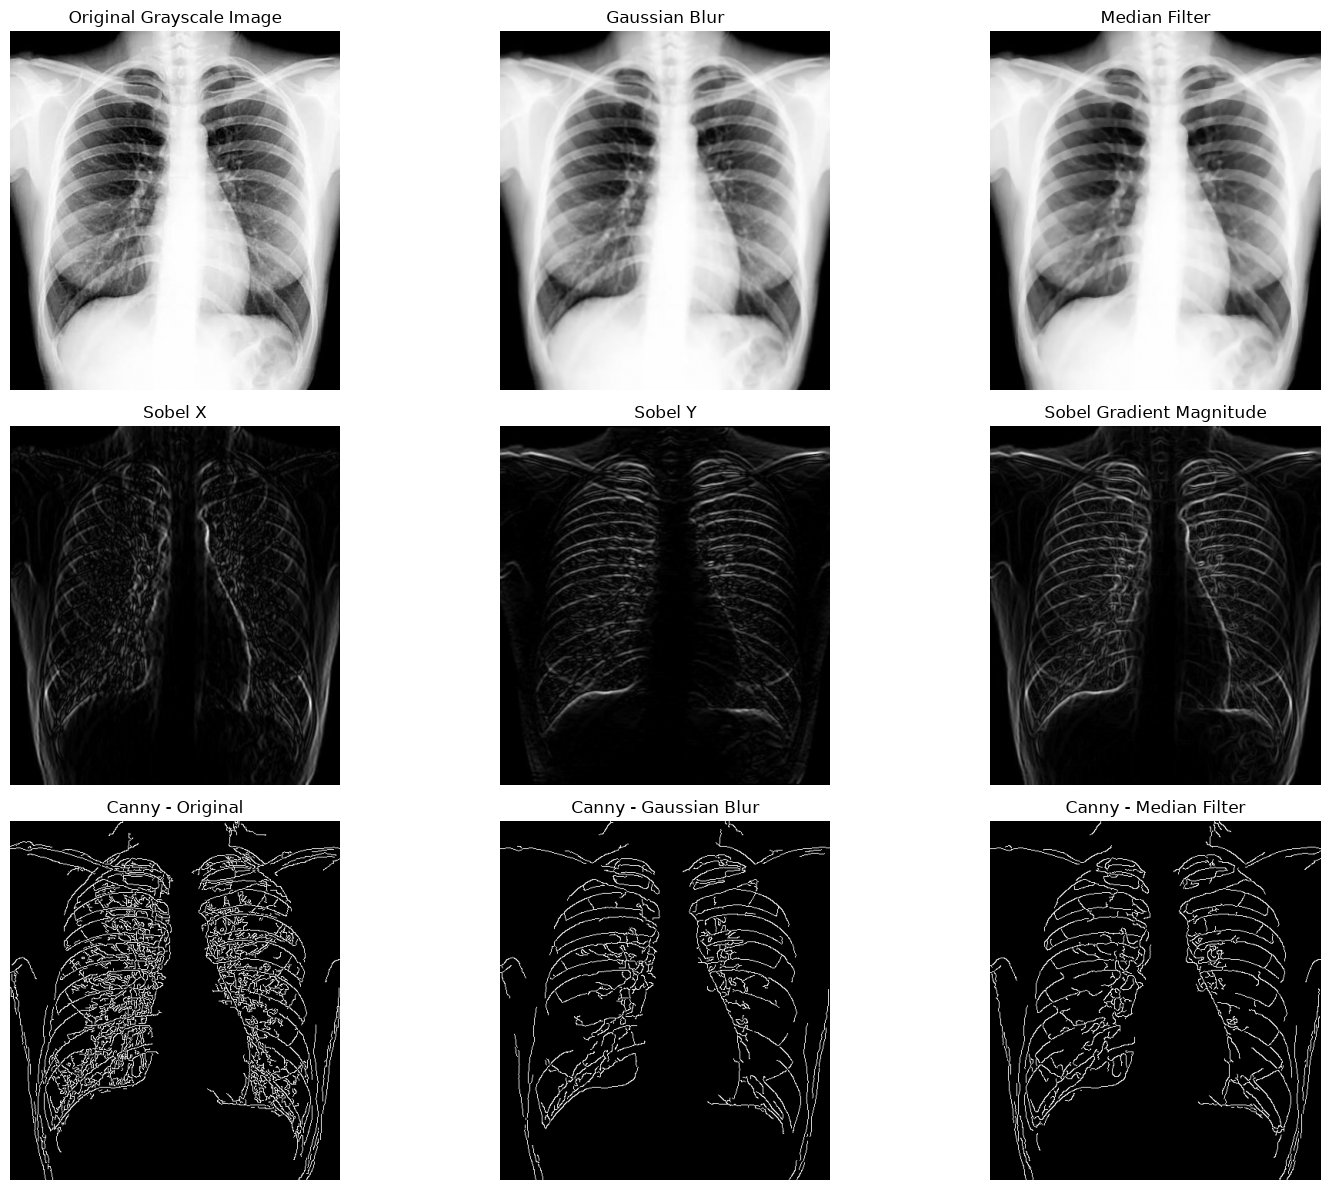

In [8]:
plt.figure(figsize=(16, 12))

# 1. Original grayscale image
plt.subplot(3, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

# 2. Gaussian Blur
plt.subplot(3, 3, 2)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

# 3. Median Filter
plt.subplot(3, 3, 3)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

# 4. Sobel X
plt.subplot(3, 3, 4)
plt.imshow(np.abs(sobel_x), cmap="gray")
plt.title("Sobel X")
plt.axis("off")

# 5. Sobel Y
plt.subplot(3, 3, 5)
plt.imshow(np.abs(sobel_y), cmap="gray")
plt.title("Sobel Y")
plt.axis("off")

# 6. Sobel Gradient Magnitude
plt.subplot(3, 3, 6)
plt.imshow(magnitude, cmap="gray")
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

# 7. Canny on original
plt.subplot(3, 3, 7)
plt.imshow(canny_original, cmap="gray")
plt.title("Canny - Original")
plt.axis("off")

# 8. Canny after Gaussian Blur
plt.subplot(3, 3, 8)
plt.imshow(canny_gaussian, cmap="gray")
plt.title("Canny - Gaussian Blur")
plt.axis("off")

# 9. Canny after Median Filter
plt.subplot(3, 3, 9)
plt.imshow(canny_median, cmap="gray")
plt.title("Canny - Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()